# Mini-Project 4 — Rainfall Pattern & Crop Suitability Analyser

**Scenario.** An agricultural extension officer wants to compare rainfall regimes across regions and advise farmers which months suit which crops.

**Data.** Monthly rainfall (mm, Jan–Dec) for Kampala, Gulu and Mbarara from the brief (**illustrative**).

**Assumptions**
- A month is "good" for a crop if its rainfall lies inside the crop's monthly band. Below the band = *drought risk*, above = *waterlogging risk*.
- Monthly bands are derived from published **seasonal** water needs divided by season length (derivation below). They are approximations: soils, temperature and rainfall timing within the month also matter.
- CV uses the sample standard deviation (`ddof=1`).

Code: `src/rainfall.py` (classes `Region`, `CropRule`, `SimilarityAnalyser`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from pathlib import Path
from scipy.signal import find_peaks
from scipy.spatial.distance import cosine as scipy_cosine_distance

from src.rainfall import (
    MONTHS, Region, CropRule, DEFAULT_CROPS, SimilarityAnalyser, cosine_similarity,
    load_rainfall_history_csv,
)

pd.set_option("display.float_format", "{:,.3f}".format)
RAIN = {
    "Kampala": [120, 140, 180, 200, 220, 180, 90, 70, 60, 100, 110, 130],
    "Gulu":    [8, 25, 75, 160, 190, 145, 170, 215, 175, 150, 60, 15],
    "Mbarara": [70, 85, 120, 140, 90, 25, 20, 55, 100, 125, 120, 90],
}
regions = [Region(name, mm) for name, mm in RAIN.items()]

## Task 1 — The `Region` class

In [2]:
summary = pd.DataFrame([{
    "Region": r.name,
    "Annual total (mm)": r.annual_total(),
    "Mean monthly (mm)": r.mean_monthly(),
    "Wettest month": "{} ({:.0f} mm)".format(*r.wettest_month()),
    "Driest month": "{} ({:.0f} mm)".format(*r.driest_month()),
    "CV": r.coefficient_of_variation(),
} for r in regions]).set_index("Region")
summary

,Annual total (mm),Mean monthly (mm),Wettest month,Driest month,CV
Region,,,,,
Kampala,"1,600.000",133.333,May (220 mm),Sep (60 mm),0.388
Gulu,"1,388.000",115.667,Aug (215 mm),Jan (8 mm),0.642
Mbarara,"1,040.000",86.667,Apr (140 mm),Jul (20 mm),0.444


Kampala is the wettest and most even (lowest CV). Gulu has a similar total but concentrated in fewer months (highest CV, with a near-rainless December–January). Mbarara is the driest, with a pronounced mid-year dry spell.

## Task 2 — `CropRule`: suitable monthly rainfall per crop (with sources)

| Crop | Published requirement | Season length | Monthly band used |
|---|---|---|---|
| Maize | 500–800 mm per season (FAO) | 125–180 days (≈ 4–6 months) | 500/5 ≈ **100** to 800/4 = **200** mm |
| Beans (dry) | 300–500 mm per season (FAO) | 95–110 days (≈ 3.5 months) | 300/3.5 ≈ **85** to 500/3.5 ≈ **145** mm |
| Robusta coffee | 1,200–1,800 mm/yr, well distributed over 9 months (UCDA) | perennial | 1200/12 = **100** to 1800/9 = **200** mm, plus an annual total of 1,200–1,800 mm |

Sources: FAO, *Water Harvesting* (Critchley & Siegert, 1991), ch. 2, Table 2 (seasonal crop water needs) and Table 6 (growing periods), <https://www.fao.org/3/U3160E/u3160e04.htm>. FAO Land & Water *Crop Information: Maize* ("waterlogging should be avoided, particularly during flowering"). Uganda Coffee Development Authority, *Robusta Coffee Handbook* ("Robusta requires a rainfall range of 1,200 mm to 1,800 mm, which is well distributed over a period of 9 months").

In [3]:
for crop in DEFAULT_CROPS:
    print(f"{crop.crop:18s} {crop.min_mm:>4.0f}–{crop.max_mm:<4.0f} mm/month   annual range: {crop.annual_range}")

labels = {}
for r in regions:
    for crop in DEFAULT_CROPS:
        labels[(r.name, crop.crop)] = crop.classify_region(r)
class_table = pd.DataFrame(labels, index=MONTHS).T
class_table.index.names = ["Region", "Crop"]
# Short codes for display: the full labels (e.g. 'Good for maize') are in class_table
class_table.apply(lambda col: col.map(lambda s: "Good" if s.startswith("Good") else s.replace(" risk", "")))

maize               100–200  mm/month   annual range: None
beans                85–145  mm/month   annual range: None
coffee (Robusta)    100–200  mm/month   annual range: (1200, 1800)


Jan      Feb           Mar           Apr  \
Region  Crop                                                             
Kampala maize                Good     Good          Good          Good   
        beans                Good     Good  Waterlogging  Waterlogging   
        coffee (Robusta)     Good     Good          Good          Good   
Gulu    maize             Drought  Drought       Drought          Good   
        beans             Drought  Drought       Drought  Waterlogging   
        coffee (Robusta)  Drought  Drought       Drought          Good   
Mbarara maize             Drought  Drought          Good          Good   
        beans             Drought     Good          Good          Good   
        coffee (Robusta)  Drought  Drought          Good          Good   

                                   May           Jun           Jul  \
Region  Crop                                                         
Kampala maize             Waterlogging          Good       Drought   
        beans             Waterlogging  Waterlogging          Good   
        coffee (Robusta)  Waterlogging          Good       Drought   
Gulu    maize                     Good          Good          Good   
        beans             Waterlogging          Good  Waterlogging   
        coffee (Robusta)          Good          Good          Good   
Mbarara maize                  Drought       Drought       Drought   
        beans                     Good       Drought       Drought   
        coffee (Robusta)       Drought       Drought       Drought   

                                   Aug           Sep           Oct      Nov  \
Region  Crop                                                                  
Kampala maize                  Drought       Drought          Good     Good   
        beans                  Drought       Drought          Good     Good   
        coffee (Robusta)       Drought       Drought          Good     Good   
Gulu    maize             Waterlogging          Good          Good  Drought   
        beans             Waterlogging  Waterlogging  Waterlogging  Drought   
        coffee (Robusta)  Waterlogging          Good          Good  Drought   
Mbarara maize                  Drought          Good          Good     Good   
        beans                  Drought          Good          Good     Good   
        coffee (Robusta)       Drought          Good          Good     Good   

                              Dec  
Region  Crop                       
Kampala maize                Good  
        beans                Good  
        coffee (Robusta)     Good  
Gulu    maize             Drought  
        beans             Drought  
        coffee (Robusta)  Drought  
Mbarara maize             Drought  
        beans                Good  
        coffee (Robusta)  Drought

In [4]:
coffee = DEFAULT_CROPS[2]
for r in regions:
    print(f"{r.name:8s}: annual {r.annual_total():,.0f} mm -> within Robusta's 1,200–1,800 mm? {coffee.annual_suitable(r)}")

Kampala : annual 1,600 mm -> within Robusta's 1,200–1,800 mm? True
Gulu    : annual 1,388 mm -> within Robusta's 1,200–1,800 mm? True
Mbarara : annual 1,040 mm -> within Robusta's 1,200–1,800 mm? False


## Task 3 — Correcting last year's cosine similarity

`math.cos(x)` returns the cosine of an **angle** $x$ (in radians). It says nothing about how similar two rainfall *vectors* are. Cosine similarity is the cosine of the angle **between** the vectors, computed from their coordinates:

$$\cos\theta = \frac{\mathbf a\cdot\mathbf b}{\lVert\mathbf a\rVert\,\lVert\mathbf b\rVert}$$

SciPy's `distance.cosine` returns the cosine **distance** $1-\cos\theta$, so we compare against `1 - scipy_cosine_distance`.

In [5]:
a, b = regions[0].rainfall, regions[1].rainfall
ours = cosine_similarity(a, b)
by_hand = a @ b / (np.sqrt(a @ a) * np.sqrt(b @ b))
scipy_value = 1 - scipy_cosine_distance(a, b)
print(f"Kampala vs Gulu  ours = {ours:.6f} | dot/norms by hand = {by_hand:.6f} | 1 - scipy cosine = {scipy_value:.6f}")
assert np.isclose(ours, scipy_value)

import math
print(f"What last year's method actually computed, e.g. math.cos(120) = {math.cos(120):.4f}: the cosine of 120 radians, meaningless here.")

Kampala vs Gulu  ours = 0.786609 | dot/norms by hand = 0.786609 | 1 - scipy cosine = 0.786609
What last year's method actually computed, e.g. math.cos(120) = 0.8142: the cosine of 120 radians, meaningless here.


## Task 4 — Similarity and distance matrices

In [6]:
sa = SimilarityAnalyser(regions)
names = sa.names
for metric, unit in [("cosine", "similarity, 0–1"), ("pearson", "correlation, −1 to 1"), ("euclidean", "distance, mm")]:
    print(f"\n{metric.title()} ({unit})")
    display(pd.DataFrame(sa.matrix(metric), index=names, columns=names).round(3))


Cosine (similarity, 0–1)


,Kampala,Gulu,Mbarara
Kampala,1.000,0.787,0.891
Gulu,0.787,1.000,0.749
Mbarara,0.891,0.749,1.000



Pearson (correlation, −1 to 1)


,Kampala,Gulu,Mbarara
Kampala,1.000,-0.066,0.209
Gulu,-0.066,1.000,-0.174
Mbarara,0.209,-0.174,1.000



Euclidean (distance, mm)


,Kampala,Gulu,Mbarara
Kampala,0.000,315.268,250.400
Gulu,315.268,0.000,312.800
Mbarara,250.400,312.800,0.000


In [7]:
# Demonstration: a region with Mbarara's pattern but 3x the rain
wet = Region("Mbarara x3", np.array(RAIN["Mbarara"]) * 3)
demo = SimilarityAnalyser([regions[2], wet])
print(f"Mbarara vs 3x-wetter copy: cosine = {demo.matrix('cosine')[0,1]:.3f}, "
      f"Pearson = {demo.matrix('pearson')[0,1]:.3f}, Euclidean = {demo.matrix('euclidean')[0,1]:,.0f} mm")

Mbarara vs 3x-wetter copy: cosine = 1.000, Pearson = 1.000, Euclidean = 652 mm


**Why cosine similarity can call a wet and a dry region "similar".** Cosine similarity depends only on the **direction** of the vectors, not their length. Scaling a region's rainfall by 3 leaves the angle unchanged, so the cosine stays exactly 1 even though the copy receives 2,000 mm more rain a year. Rainfall is also always positive, so every vector points into the same "corner" of 12-D space and cosine similarities are high by construction (here 0.75–0.89 even for very different regimes).

The three measures answer different questions:
- **Cosine**: do the two regions have the same *overall shape*, ignoring the amount?
- **Pearson**: do they rise and fall *in the same months*? Pearson subtracts each region's mean first. Kampala vs Gulu has cosine 0.79 but Pearson ≈ −0.07: Gulu's wettest months (Jul–Sep) are Kampala's driest.
- **Euclidean**: how many mm apart are they, month by month? This is the only one of the three that is sensitive to amount.

For crop advice, amount matters, so Euclidean distance (or comparing against crop thresholds) is more relevant than cosine.

## Task 5 — Detecting rainy seasons with `scipy.signal.find_peaks`

In [8]:
naive = {r.name: [MONTHS[p] for p in find_peaks(r.rainfall)[0]] for r in regions}
robust = {r.name: [MONTHS[p] for p in r.rainy_season_peaks(prominence_frac=0.25)] for r in regions}
pd.DataFrame({
    "naive find_peaks (no wrap, no prominence)": naive,
    "our method (circular year, prominence ≥ 25% of range)": robust,
    "regime": {r.name: r.regime() for r in regions},
    "known climate zone": {"Kampala": "bimodal (MAM & SON rains)", "Gulu": "unimodal (Apr–Oct)", "Mbarara": "bimodal (MAM & SON rains)"},
})

,"naive find_peaks (no wrap, no prominence)","our method (circular year, prominence ≥ 25% of range)",regime,known climate zone
Kampala,[May],[May],unimodal,bimodal (MAM & SON rains)
Gulu,"[May, Aug]",[Aug],unimodal,unimodal (Apr–Oct)
Mbarara,"[Apr, Oct]","[Apr, Oct]",bimodal,bimodal (MAM & SON rains)


**Method choices.**
1. **Circular year.** `find_peaks` never reports the first or last array element as a peak, so a December peak would be invisible. We tile the year three times and keep peaks from the middle copy.
2. **Prominence threshold.** Plain `find_peaks` counts every small wiggle. Gulu's June dip (190 → 145 → 170 mm) would split its one long season into two, and Kampala's small December bump (+10 mm) would count as a season. Requiring a peak to stand out by at least 25 % of the region's annual range removes these.

**Check against Uganda's climate zones.** Gulu → **unimodal** ✓ (northern Uganda has one long rainy season, roughly April–October). Mbarara → **bimodal** ✓ (south-west: March–May and September–November rains). Kampala → **unimodal** ✗: the Lake Victoria basin is known to be bimodal, but in the *illustrative* series the September–November rise (60 → 130 mm) is weak and has no clear peak before it merges into the next year's rains. The algorithm is behaving correctly and the data do not show the second season clearly. This is a limitation of the illustrative data, and one reason to use real rainfall (extension). With a lower threshold (e.g. `prominence_frac=0.05`), Kampala's December bump would count and it would be classed as bimodal, which shows how sensitive the classification is to this setting.

In [9]:
print("Sensitivity: Kampala peaks at different prominence thresholds")
for frac in [0.0, 0.05, 0.10, 0.25, 0.40]:
    print(f"  {frac:>4.0%}: {[MONTHS[p] for p in regions[0].rainy_season_peaks(frac)]} -> {regions[0].regime(frac)}")

Sensitivity: Kampala peaks at different prominence thresholds
    0%: ['May', 'Dec'] -> bimodal
    5%: ['May', 'Dec'] -> bimodal
   10%: ['May'] -> unimodal
   25%: ['May'] -> unimodal
   40%: ['May'] -> unimodal


## Task 6 — Visualisation

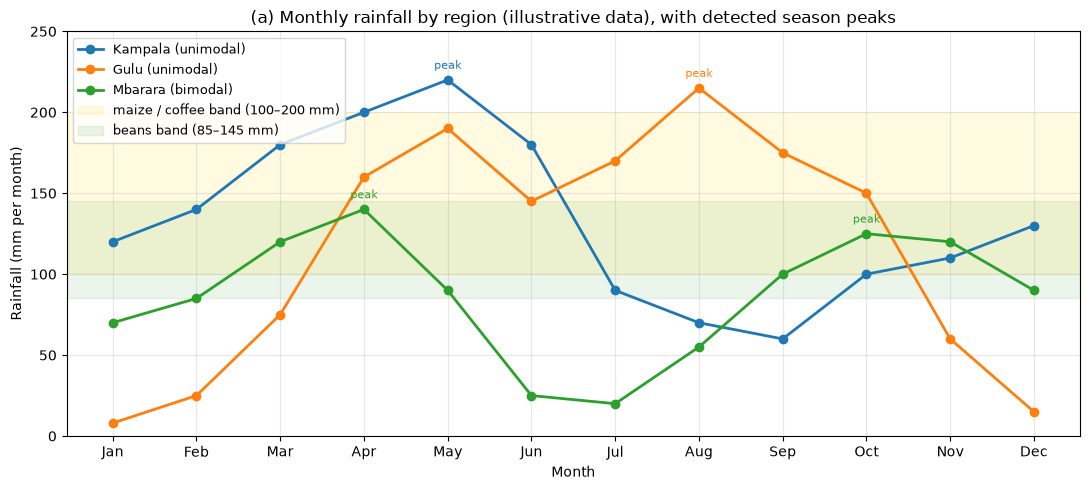

In [10]:
fig, ax = plt.subplots(figsize=(11, 5))
colours = {"Kampala": "tab:blue", "Gulu": "tab:orange", "Mbarara": "tab:green"}
for r in regions:
    ax.plot(MONTHS, r.rainfall, "o-", lw=2, color=colours[r.name], label=f"{r.name} ({r.regime()})")
    for p in r.rainy_season_peaks():
        ax.annotate("peak", (p, r.rainfall[p]), textcoords="offset points", xytext=(0, 8), ha="center",
                    fontsize=8, color=colours[r.name])
ax.axhspan(100, 200, color="gold", alpha=0.12, label="maize / coffee band (100–200 mm)")
ax.axhspan(85, 145, color="green", alpha=0.08, label="beans band (85–145 mm)")
ax.set(title="(a) Monthly rainfall by region (illustrative data), with detected season peaks",
       xlabel="Month", ylabel="Rainfall (mm per month)", ylim=(0, 250))
ax.legend(fontsize=9, loc="upper left"); ax.grid(alpha=0.3)
fig.tight_layout(); fig.savefig("figures/p4_rainfall_lines.png", dpi=150); plt.show()

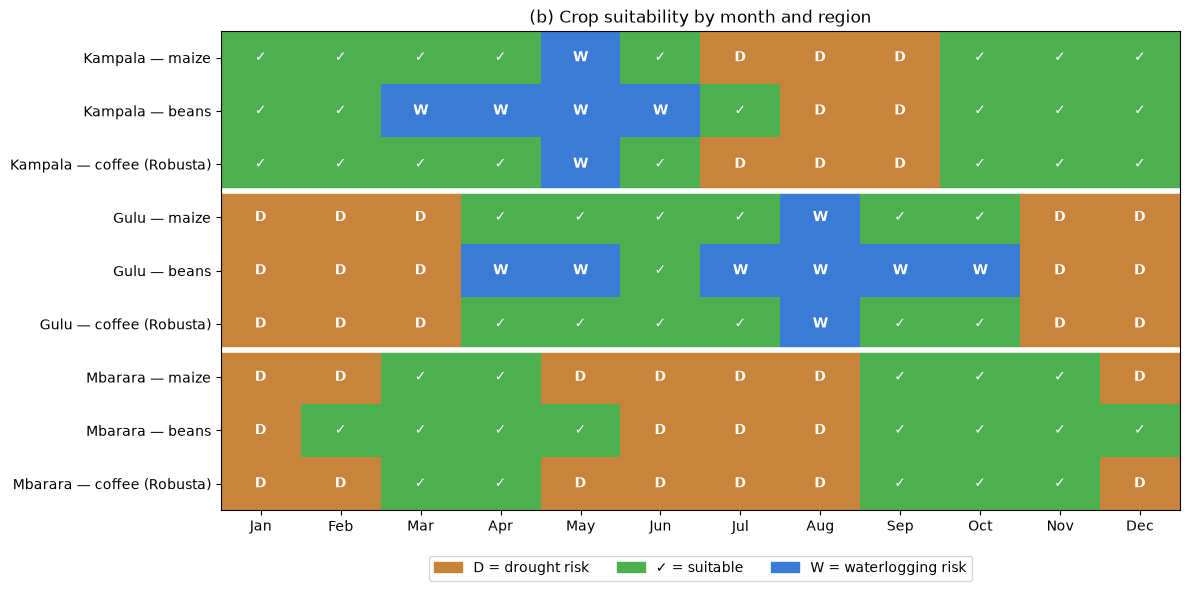

In [11]:
rows, row_labels = [], []
for r in regions:
    for crop in DEFAULT_CROPS:
        rows.append([crop.score(v) for v in r.rainfall])
        row_labels.append(f"{r.name} — {crop.crop}")
scores = np.array(rows)

cmap = ListedColormap(["#c8843a", "#4caf50", "#3a7bd5"])        # dry / good / wet
fig, ax = plt.subplots(figsize=(12, 6))
ax.imshow(scores, cmap=cmap, vmin=-1, vmax=1, aspect="auto")
symbols = {-1: "D", 0: "✓", 1: "W"}
for i in range(scores.shape[0]):
    for j in range(12):
        ax.text(j, i, symbols[scores[i, j]], ha="center", va="center", color="white", fontsize=10, fontweight="bold")
ax.set_xticks(range(12), MONTHS)
ax.set_yticks(range(len(row_labels)), row_labels)
for y in (2.5, 5.5):
    ax.axhline(y, color="white", lw=4)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color="#c8843a", label="D = drought risk"), Patch(color="#4caf50", label="✓ = suitable"),
                   Patch(color="#3a7bd5", label="W = waterlogging risk")],
          loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=3)
ax.set_title("(b) Crop suitability by month and region")
fig.tight_layout(); fig.savefig("figures/p4_suitability_heatmap.png", dpi=150); plt.show()

In [12]:
good_months = pd.DataFrame({crop.crop: {r.name: int((np.array([crop.score(v) for v in r.rainfall]) == 0).sum()) for r in regions}
                            for crop in DEFAULT_CROPS})
good_months.index.name = "Suitable months per year"
good_months

,maize,beans,coffee (Robusta)
Suitable months per year,,,
Kampala,8,6,8
Gulu,6,1,6
Mbarara,5,8,5


## Task 7 — Advisory note for farmers in **Mbarara**

> **Rainfall advisory: Mbarara (illustrative rainfall)**
>
> Mbarara has **two rainy seasons**, peaking in April and October (usable rain February–May and September–December), with a dry spell from May to August (only 20–25 mm in June–July). Total rain is about 1,040 mm a year, lower than Kampala or Gulu.
>
> **Recommended crop: beans.** Beans need less water than maize and mature in about 3½ months, so they fit inside each short season. Rainfall suits beans in **8 of 12 months**, compared with only 5 for maize.
>
> **When to plant:**
> - **Season A:** plant beans with the first reliable rains in **mid-February to early March**, and harvest in **May–June**, before the dry spell.
> - **Season B:** plant in **late August to early September**, and harvest in **December**.
>
> **Avoid** planting maize for the dry spell. May–August is too dry for a 4–6-month maize crop to finish. If you grow maize, plant it only at the very start of the September rains and choose a short-season variety.
>
> Mbarara's annual rain is below the 1,200 mm that Robusta coffee needs, so new coffee should only be planted with mulching or irrigation.

*(≈ 190 words)*

## Extension — Real rainfall (NASA POWER) and year-to-year variability

`scripts/fetch_nasa_rainfall.py` downloads 2014–2023 monthly rainfall (NASA POWER, bias-corrected precipitation `PRECTOTCORR`) for the three towns into `data/nasa_power_rainfall.csv`. **It needs an internet connection and must be run once** (`python scripts/fetch_nasa_rainfall.py`). The cell below then draws box plots of the monthly spread. If the file is missing, it prints instructions instead of failing, so *Restart & Run All* still works offline.

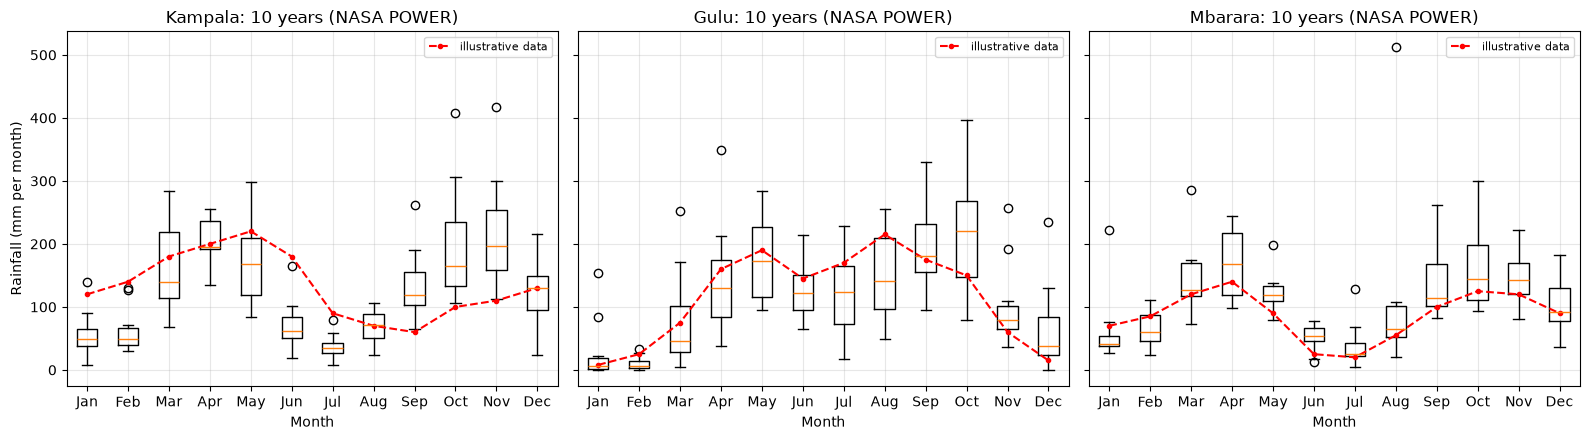

Kampala (NASA mean)    annual 1,506 mm, regime: bimodal, peaks: ['Apr', 'Nov']
Gulu (NASA mean)       annual 1,416 mm, regime: bimodal, peaks: ['May', 'Oct']
Mbarara (NASA mean)    annual 1,314 mm, regime: bimodal, peaks: ['Apr', 'Oct']


In [13]:
hist_path = Path("data/nasa_power_rainfall.csv")
if hist_path.exists():
    history = load_rainfall_history_csv(hist_path)
    fig, axes = plt.subplots(1, len(history), figsize=(16, 4.5), sharey=True)
    for ax, (name, arr) in zip(np.atleast_1d(axes), history.items()):
        ax.boxplot([arr[:, m][~np.isnan(arr[:, m])] for m in range(12)])
        ax.set_xticks(range(1, 13), MONTHS)
        ax.plot(range(1, 13), RAIN.get(name, [np.nan] * 12), "r.--", label="illustrative data")
        ax.set(title=f"{name}: {arr.shape[0]} years (NASA POWER)", xlabel="Month")
        ax.grid(alpha=0.3); ax.legend(fontsize=8)
    np.atleast_1d(axes)[0].set_ylabel("Rainfall (mm per month)")
    fig.tight_layout(); fig.savefig("figures/p4_nasa_boxplots.png", dpi=150); plt.show()
    for name, arr in history.items():
        real = Region(name + " (NASA mean)", np.nanmean(arr, axis=0))
        print(f"{real.name:22s} annual {real.annual_total():,.0f} mm, regime: {real.regime()}, peaks: {[MONTHS[p] for p in real.rainy_season_peaks()]}")
else:
    print("Real-data file not found. Run `python scripts/fetch_nasa_rainfall.py` once (needs internet),\n"
          "then re-run this notebook to add the box plots.")

## Findings & Limitations

**Findings.** The three regions differ more in the *timing* of their rain than in the amount, and that timing drives crop advice. Kampala is the wettest and most even (1,600 mm, CV 0.39): maize and coffee are suitable in 8 months, while beans risk waterlogging in the March–June peak. Gulu has one long season (April–October) and a severe December–February drought. Its rain is heavy enough for maize but too heavy for beans (suitable in only 1 month). Mbarara is bimodal and the driest (1,040 mm). Its two short seasons suit beans (8 months) far better than maize (5), and it falls below Robusta coffee's 1,200 mm minimum. The comparison of similarity measures shows why method choice matters. Cosine similarity rated Kampala and Gulu 0.79 "similar" because rainfall vectors are all positive and cosine ignores amount. Pearson correlation (−0.07) shows their wet months do not coincide at all. For advising farmers, month-by-month distance and threshold checks are more meaningful than cosine. Peak detection correctly separated unimodal Gulu from bimodal Mbarara, but only after we treated the year as circular and added a prominence threshold. Naïve `find_peaks` would have split Gulu's single season in two.

**Limitations.** (1) The data are one illustrative "typical" year, which hides the year-to-year variability that farmers actually face. Kampala's weak second season, which led our method to call it unimodal against known climatology, is a symptom of this. (2) Monthly bands derived from seasonal totals ignore when rain falls within a crop's life (e.g. flowering), soil drainage and evaporation. (3) The 25 % prominence threshold is a judgement call: at 5 % Kampala becomes bimodal. (4) The real-data extension is implemented but needs internet access to fetch NASA POWER data.